In [72]:
import numpy as np
from proflib import load_profdata
import matplotlib.pyplot as plt
import seaborn as sns

In [88]:
data = load_profdata('build/boom_l_1.T7/prof/linux.bin')

In [89]:
def convert_data(data):
    rdtsc_ticks = []
    for thread in data.threads:
        rdtsc_ticks.append(thread.rdtsc_ticks)
    num_threads = len(data.threads)
    rdtsc_ticks = np.array(rdtsc_ticks).reshape(num_threads, -1, 6)
    step_elapsed = np.diff(rdtsc_ticks, axis=-1)
    step_pivot = np.concatenate(
        [
            step_elapsed[:, :, [2,4]].sum(axis=-1, keepdims=True),
            step_elapsed[:, :, [0,1,3]].sum(axis=-1, keepdims=True),
            # step_elapsed[:, :, [1]].sum(axis=-1, keepdims=True),
            # step_elapsed[:, :, [2]].sum(axis=-1, keepdims=True),
            # step_elapsed[:, :, [3]].sum(axis=-1, keepdims=True),
            # step_elapsed[:, :, [4]].sum(axis=-1, keepdims=True),
        ],
        axis=-1
    )
    step_names = ['busy', 'idle']
    # step_names = ['1', '2', '3', '4', '5']
    return step_pivot, step_names

In [90]:
def plot_stack_bar(data, include_avg=False, colors=None):
    stack = np.cumsum(data, axis=1)
    xlabels = [f'T{i+1}' for i in range(data.shape[0])]
    x = np.arange(data.shape[0])
    if include_avg:
        avg = data.mean(axis=0)
        data = np.concatenate([data, avg[None]], axis=0)
        xsep = x[-1] + 1.25 / 2
        x = np.concatenate([x, [x[-1] + 1.25]])
        plt.axvline(xsep, color='k', lw=0.5)
        xlabels.append('Avg.')
    stack = np.cumsum(data, axis=1)
    data_pct = data / data.sum(axis=1, keepdims=True)
    handles = []
    for i in range(data.shape[1]):
        bottom = np.zeros(data.shape[0]) if i == 0 else stack[:, i-1]
        color = colors[i] if colors else None
        h = plt.bar(x, data[:, i], width=0.5, bottom=bottom, color=color)
        for j in range(data.shape[0]):
            plt.text(
                x[j],
                bottom[j] + data[:, i][j] / 2,
                f'{data_pct[:, i][j]:.0%}',
                ha='center',
                va='center',
                color='k',
                fontsize=8,
            )
        handles.append(h)
    plt.xticks(x, xlabels)
    return handles

In [91]:
cmap = sns.color_palette("deep", 10)
cmap

[(0.2980392156862745, 0.4470588235294118, 0.6901960784313725),
 (0.8666666666666667, 0.5176470588235295, 0.3215686274509804),
 (0.3333333333333333, 0.6588235294117647, 0.40784313725490196),
 (0.7686274509803922, 0.3058823529411765, 0.3215686274509804),
 (0.5058823529411764, 0.4470588235294118, 0.7019607843137254),
 (0.5764705882352941, 0.47058823529411764, 0.3764705882352941),
 (0.8549019607843137, 0.5450980392156862, 0.7647058823529411),
 (0.5490196078431373, 0.5490196078431373, 0.5490196078431373),
 (0.8, 0.7254901960784313, 0.4549019607843137),
 (0.39215686274509803, 0.7098039215686275, 0.803921568627451)]

Text(0, 0.5, 'CPU Cycles')

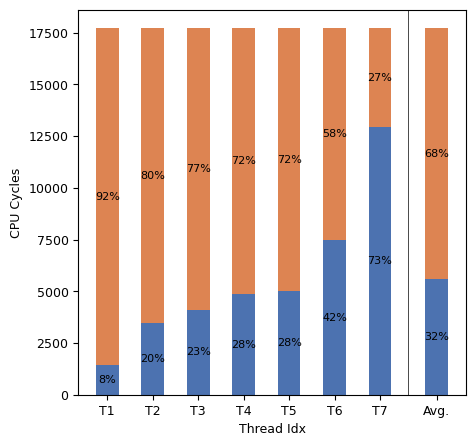

In [92]:
plt.figure(figsize=(5, 5))
colors = [cmap[0], cmap[1], cmap[2], cmap[3]]
step_pivot, step_names = convert_data(data)
step_mean = step_pivot.mean(axis=1)
argidx = np.argsort(step_mean[:, 0])
step_mean = step_mean[argidx]
plot_stack_bar(step_mean, colors=colors, include_avg=True)
plt.xlabel('Thread Idx')
plt.ylabel('CPU Cycles')